<a href="https://colab.research.google.com/github/miguelmartinezm-gwu/miguel.martinez.github.io/blob/main/DataMiningFinalProject_Corrected_Improved_Rev_11_21_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miguelmartinezm-gwu/miguel.martinez.github.io/blob/main/DataMiningFinalProject_Corrected_Improved_Rev_11_21_2026.ipynb)

# Disclaimer Cell

In [75]:
# ============================================================
# PROJECT SCOPE & DISCLAIMER — READ BEFORE USING ANY OUTPUT BELOW
# ============================================================
print("="*70)
print("WHAT THIS MODEL IS")
print("="*70)
print("""
A data-mining classifier that estimates the PROBABILITY of a large
next-day move in the S&P 500 (SPY), defined as |next-day return| > 1%.
Final configuration: Random Forest, 25 features (technical + FRED
macro), trained on 10 years of daily data with the 2020 COVID window
excluded, threshold selected via Youden's J statistic on the ROC curve.

Validated performance (walk-forward, folds 2-8): Balanced Accuracy
0.666 ± 0.053, Recall 0.699 ± 0.175, Precision 0.400 ± 0.062.

BEST USE: a risk-awareness / capital-preservation filter — specifically,
deciding whether conditions favor a neutral, defined-risk options
structure (e.g., an Iron Condor) or argue against opening one.
""")

print("="*70)
print("WHAT THIS MODEL IS NOT")
print("="*70)
print("""
- NOT a directional predictor. Tested explicitly (M11): direction
  after a Big-Down day is 54.3% Up vs. 55.6% unconditional — no
  exploitable edge. Do not use this model's output to choose puts
  vs. calls, or to justify a directional bet of any kind.
- NOT aware of earnings or scheduled macro events beyond what a
  free calendar lookup can flag (M8); the Oct 29-30 2026 miss (M7)
  was caused by an overnight earnings shock this model structurally
  cannot see.
- NOT accounting for options-specific risk: implied volatility
  level/rank, bid-ask spreads, assignment risk, margin requirements,
  or liquidity — a "Condor allowed" signal says the index-level
  regime looks quiet, not that any specific strike/expiry is well
  priced.
- NOT a complete risk model for SPY's concentration: ~10 mega-cap
  names carry a large share of index weight (M8-C); a single-name
  shock in any of them can move the index regardless of what this
  model's broad features say.
- NOT financial advice, and not validated for live capital. This is
  an academic data-mining project; recall of ~0.70 still means
  roughly 1 in 3 actual Big Moves are missed, and precision of ~0.40
  means roughly 3 in 5 "Big Move" alerts are false alarms.
""")
print("="*70)

WHAT THIS MODEL IS

A data-mining classifier that estimates the PROBABILITY of a large
next-day move in the S&P 500 (SPY), defined as |next-day return| > 1%.
Final configuration: Random Forest, 25 features (technical + FRED
macro), trained on 10 years of daily data with the 2020 COVID window
excluded, threshold selected via Youden's J statistic on the ROC curve.

Validated performance (walk-forward, folds 2-8): Balanced Accuracy
0.666 ± 0.053, Recall 0.699 ± 0.175, Precision 0.400 ± 0.062.

BEST USE: a risk-awareness / capital-preservation filter — specifically,
deciding whether conditions favor a neutral, defined-risk options
structure (e.g., an Iron Condor) or argue against opening one.

WHAT THIS MODEL IS NOT

- NOT a directional predictor. Tested explicitly (M11): direction
  after a Big-Down day is 54.3% Up vs. 55.6% unconditional — no
  exploitable edge. Do not use this model's output to choose puts
  vs. calls, or to justify a directional bet of any kind.
- NOT aware of earnings

# O1 - Setup

In [76]:
!pip install -q pandas_datareader

In [77]:
# ============================================================
# M0 — SETUP
# ============================================================
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

print("M0 complete — libraries loaded")

from zoneinfo import ZoneInfo
ET = ZoneInfo("America/New_York")

M0 complete — libraries loaded


# 01 - Data Ingestion (Yahoo Finance)

In [78]:
# ============================================================
# M1 — DATA INGESTION (SPY + FRED, unified)
# ============================================================
M1_FRED_SERIES = {
    'VIXCLS': 'vix', 'DGS10': 't10', 'DGS2': 't2', 'DGS30': 't30',
    'T10Y2Y': 'curve_10_2', 'T10Y3M': 'curve_10_3m',
    'BAA10Y': 'credit_spread', 'DFF': 'fed_funds'
}

def m1_fetch_raw(start, end):
    """Fetch SPY OHLCV + merged FRED macro series for the given window."""
    if getattr(start, 'tzinfo', None) is not None:
        start = start.replace(tzinfo=None)
    if getattr(end, 'tzinfo', None) is not None:
        end = end.replace(tzinfo=None)

    spy = yf.download("SPY", start=start, end=end, auto_adjust=True, progress=False)[
        ['Open','High','Low','Close','Volume']]
    spy.columns = ['open','high','low','close','volume']
    spy = spy.reset_index().rename(columns={'Date':'datetime'})
    spy['datetime'] = pd.to_datetime(spy['datetime'])

    fred = web.DataReader(list(M1_FRED_SERIES.keys()), 'fred', start, end)
    fred = fred.rename(columns=M1_FRED_SERIES).reset_index().rename(columns={'DATE':'datetime'})
    fred['datetime'] = pd.to_datetime(fred['datetime'])
    fred = fred.set_index('datetime').ffill().reset_index()

    merged = pd.merge(spy, fred, on='datetime', how='left')
    fred_cols = [c for c in fred.columns if c != 'datetime']
    merged[fred_cols] = merged[fred_cols].ffill()
    return merged.dropna(subset=['close','vix','t10']).copy()

# Full 5-year history for training
M1_END = datetime.now(ET)
M1_START = M1_END - timedelta(days=5*365 + 60)

m1_raw = m1_fetch_raw(M1_START, M1_END)

print(f"M1 complete — shape: {m1_raw.shape}")
print(f"Date range: {m1_raw['datetime'].min().date()} → {m1_raw['datetime'].max().date()}")
m1_raw.tail(3)

M1 complete — shape: (1295, 14)
Date range: 2021-10-01 → 2026-11-27


,datetime,open,high,low,close,volume,vix,t10,t2,t30,curve_10_2,curve_10_3m,credit_spread,fed_funds
1293,2026-11-24,715.150024,720.929993,712.140015,718.780029,64343200,26.36,4.91,4.63,5.30,0.28,0.55,1.61,3.88
1294,2026-11-25,703.200012,718.429993,695.450012,716.700012,73112800,28.29,4.85,4.61,5.24,0.24,0.51,1.61,3.88
1295,2026-11-27,725.859985,729.150024,719.609985,728.320007,40442200,26.80,4.85,4.61,5.24,0.25,0.59,1.61,3.88


In [79]:
# ============================================================
# M1-B — 10-YEAR DATA (ablation: does more history help or hurt?)
# ============================================================
M1B_END = datetime.now(ET)
M1B_START = M1B_END - timedelta(days=10*365 + 60)

m1b_raw = m1_fetch_raw(M1B_START, M1B_END)

print(f"M1-B complete — shape: {m1b_raw.shape}")
print(f"Date range: {m1b_raw['datetime'].min().date()} → {m1b_raw['datetime'].max().date()}")

# Flag the COVID stress window so we can see its effect explicitly later
covid_mask = (m1b_raw['datetime'] >= '2020-02-15') & (m1b_raw['datetime'] <= '2020-05-01')
print(f"COVID-window rows included: {covid_mask.sum()}")

M1-B complete — shape: (2553, 14)
Date range: 2016-10-03 → 2026-11-27
COVID-window rows included: 53


# 02 - Feature Engineering (Yahoo Finance)

In [80]:
# ============================================================
# M2 — FEATURE ENGINEERING (unified, used for training AND live scoring)
# ============================================================
M2_FEATURES = [
    'ret_1','ret_3','ret_5','mom_10','mom_20',
    'vol_10','vol_20','vol_ratio','parkinson_10','gk_10','overnight_gap',
    'vix','vix_change','vix_z',
    't10','t10_change','t2','t2_change','t30',
    'curve_10_2','curve_change','curve_10_3m',
    'credit_spread','credit_change','fed_funds'
]

def m2_build_features(df, with_target=True):
    """Identical feature construction for training and live scoring — never duplicate this logic elsewhere."""
    df = df.copy()
    df['log_ret'] = np.log(df['close'] / df['close'].shift(1))
    if with_target:
        df['target'] = (df['log_ret'].shift(-1).abs() > 0.01).astype(int)

    df['ret_1'] = df['log_ret']
    df['ret_3'] = df['log_ret'].rolling(3).sum()
    df['ret_5'] = df['log_ret'].rolling(5).sum()
    df['mom_10'] = df['close'] / df['close'].shift(10) - 1
    df['mom_20'] = df['close'] / df['close'].shift(20) - 1
    df['vol_10'] = df['log_ret'].rolling(10).std()
    df['vol_20'] = df['log_ret'].rolling(20).std()
    df['vol_ratio'] = df['vol_10'] / df['vol_20']
    df['overnight_gap'] = df['open'] / df['close'].shift(1) - 1

    hl = np.log(df['high'] / df['low'])
    df['parkinson_10'] = np.sqrt((hl**2 / (4*np.log(2))).rolling(10).mean())
    log_hl = np.log(df['high']/df['low'])**2
    log_co = np.log(df['close']/df['open'])**2
    gk = 0.5*log_hl - (2*np.log(2)-1)*log_co
    df['gk_10'] = np.sqrt(gk.rolling(10).mean().clip(lower=0))

    df['vix_change'] = df['vix'].pct_change()
    df['vix_z'] = (df['vix'] - df['vix'].rolling(20).mean()) / df['vix'].rolling(20).std()
    df['t10_change'] = df['t10'].diff()
    df['t2_change'] = df['t2'].diff()
    df['curve_change'] = df['curve_10_2'].diff()
    df['credit_change'] = df['credit_spread'].diff()

    needed = M2_FEATURES + (['target'] if with_target else [])
    return df.dropna(subset=needed).copy()

# Apply to both datasets
m2_data_5y = m2_build_features(m1_raw, with_target=True)
m2_data_10y = m2_build_features(m1b_raw, with_target=True)

m2_X_5y, m2_y_5y = m2_data_5y[M2_FEATURES], m2_data_5y['target'].astype(int)
m2_X_10y, m2_y_10y = m2_data_10y[M2_FEATURES], m2_data_10y['target'].astype(int)

print(f"M2 complete")
print(f"5-year:  shape {m2_X_5y.shape}, Big Move rate {m2_y_5y.mean():.1%}")
print(f"10-year: shape {m2_X_10y.shape}, Big Move rate {m2_y_10y.mean():.1%}")

# Quick check: is the Big Move rate meaningfully different in the 10yr set?
# (a sign of regime heterogeneity, e.g. COVID inflating the rate)
covid_mask_feat = (m2_data_10y['datetime'] >= '2020-02-15') & (m2_data_10y['datetime'] <= '2020-05-01')
print(f"\nBig Move rate during COVID window:     {m2_data_10y.loc[covid_mask_feat, 'target'].mean():.1%}")
print(f"Big Move rate excluding COVID window:  {m2_data_10y.loc[~covid_mask_feat, 'target'].mean():.1%}")

M2 complete
5-year:  shape (1275, 25), Big Move rate 27.7%
10-year: shape (2533, 25), Big Move rate 24.2%

Big Move rate during COVID window:     77.4%
Big Move rate excluding COVID window:  23.1%


# 03 - Walk-Forward Model Comparison (5yr vs 10yr vs 10yr-ex-COVID)

In [81]:
# ============================================================
# M3 — WALK-FORWARD MODEL COMPARISON
# ============================================================
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

def m3_walk_forward(model, X, y, name, scale=False, n_splits=5):
    tscv = TimeSeriesSplit(n_splits=n_splits)
    bals, f1s, precs, recs = [], [], [], []
    for tr, te in tscv.split(X):
        Xtr, Xte = X.iloc[tr].copy(), X.iloc[te].copy()
        ytr, yte = y.iloc[tr], y.iloc[te]
        if scale:
            sc = StandardScaler()
            Xtr = sc.fit_transform(Xtr)
            Xte = sc.transform(Xte)
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        bals.append(balanced_accuracy_score(yte, pred))
        f1s.append(f1_score(yte, pred, zero_division=0))
        precs.append(precision_score(yte, pred, zero_division=0))
        recs.append(recall_score(yte, pred, zero_division=0))
    print(f"{name:30} | Bal Acc: {np.mean(bals):.4f} | F1: {np.mean(f1s):.4f} | "
          f"Prec: {np.mean(precs):.3f} | Rec: {np.mean(recs):.3f}")
    return np.mean(bals), np.mean(f1s)

def m3_run_all_models(X, y, label):
    print(f"\n{'='*70}\n{label}\n{'='*70}")
    results = {}
    results['Logistic Regression'] = m3_walk_forward(
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        X, y, "Logistic Regression", scale=True)
    results['Random Forest'] = m3_walk_forward(
        RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=10,
                               class_weight='balanced', random_state=42, n_jobs=-1),
        X, y, "Random Forest", scale=False)
    results['Gradient Boosting'] = m3_walk_forward(
        GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.08,
                                   subsample=0.8, random_state=42),
        X, y, "Gradient Boosting", scale=False)
    results['MLP Neural Net'] = m3_walk_forward(
        MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, early_stopping=True, random_state=42),
        X, y, "MLP Neural Net", scale=True)
    return results

# --- Run 1: 5-year (primary) ---
m3_results_5y = m3_run_all_models(m2_X_5y, m2_y_5y, "5-YEAR DATASET")

# --- Run 2: 10-year (full, includes COVID) ---
m3_results_10y = m3_run_all_models(m2_X_10y, m2_y_10y, "10-YEAR DATASET (includes COVID)")

# --- Run 3: 10-year, COVID window excluded ---
m3_covid_mask = (m2_data_10y['datetime'] >= '2020-02-15') & (m2_data_10y['datetime'] <= '2020-05-01')
m3_X_10y_exc = m2_X_10y[~m3_covid_mask]
m3_y_10y_exc = m2_y_10y[~m3_covid_mask]
m3_results_10y_exc = m3_run_all_models(m3_X_10y_exc, m3_y_10y_exc, "10-YEAR DATASET (COVID excluded)")

# --- Summary table ---
m3_summary = pd.DataFrame({
    "Model": list(m3_results_5y.keys()),
    "5yr Bal Acc": [m3_results_5y[k][0] for k in m3_results_5y],
    "10yr Bal Acc": [m3_results_10y[k][0] for k in m3_results_10y],
    "10yr ex-COVID Bal Acc": [m3_results_10y_exc[k][0] for k in m3_results_10y_exc],
}).round(4)

print(f"\n{'='*70}\nM3 SUMMARY\n{'='*70}")
print(m3_summary.to_string(index=False))


5-YEAR DATASET
Logistic Regression            | Bal Acc: 0.5669 | F1: 0.2545 | Prec: 0.367 | Rec: 0.228
Random Forest                  | Bal Acc: 0.6038 | F1: 0.3647 | Prec: 0.427 | Rec: 0.364
Gradient Boosting              | Bal Acc: 0.5538 | F1: 0.2774 | Prec: 0.337 | Rec: 0.280
MLP Neural Net                 | Bal Acc: 0.5345 | F1: 0.1500 | Prec: 0.519 | Rec: 0.088

10-YEAR DATASET (includes COVID)
Logistic Regression            | Bal Acc: 0.6387 | F1: 0.4963 | Prec: 0.382 | Rec: 0.735
Random Forest                  | Bal Acc: 0.6683 | F1: 0.5310 | Prec: 0.432 | Rec: 0.703
Gradient Boosting              | Bal Acc: 0.5962 | F1: 0.4496 | Prec: 0.391 | Rec: 0.604
MLP Neural Net                 | Bal Acc: 0.5212 | F1: 0.1086 | Prec: 0.498 | Rec: 0.068

10-YEAR DATASET (COVID excluded)
Logistic Regression            | Bal Acc: 0.6271 | F1: 0.4673 | Prec: 0.349 | Rec: 0.755
Random Forest                  | Bal Acc: 0.6705 | F1: 0.5122 | Prec: 0.412 | Rec: 0.687
Gradient Boosting         

# 04 - Final Model + Threshold Selection (on the winning dataset)

M4 — FINAL MODEL (10yr, COVID excluded)
Threshold (Youden's J): 0.544
AUC:        0.719
Precision:  0.412
Recall:     0.602
F1:         0.489
Bal Acc:    0.674


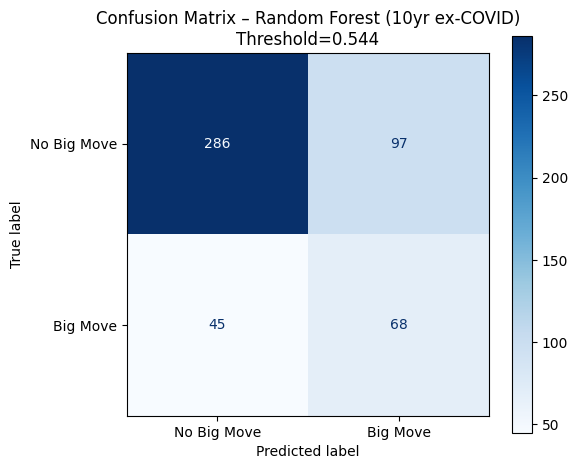

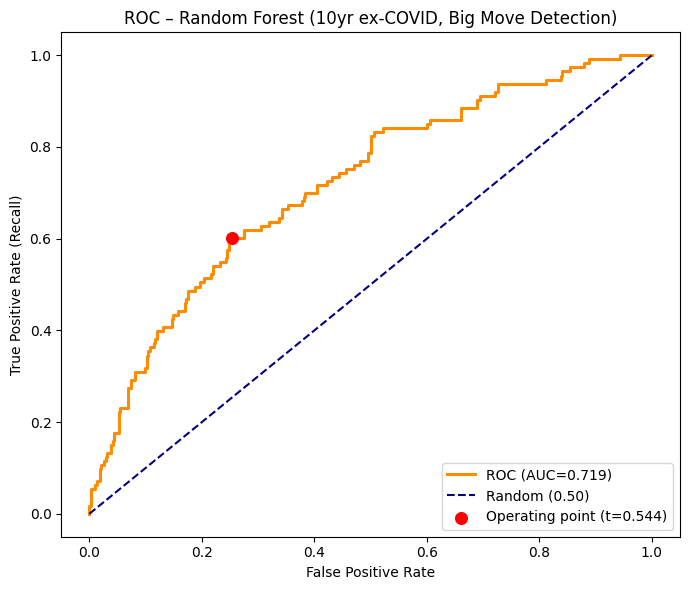


M4_MODEL retrained on full 10yr (ex-COVID) dataset for deployment.


In [82]:
# ============================================================
# M4 — FINAL MODEL + YOUDEN'S J THRESHOLD (10yr, COVID excluded)
# ============================================================
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, balanced_accuracy_score, ConfusionMatrixDisplay, confusion_matrix

m4_X = m3_X_10y_exc.reset_index(drop=True)
m4_y = m3_y_10y_exc.reset_index(drop=True)

m4_split = int(len(m4_X) * 0.80)
m4_Xtr, m4_Xte = m4_X.iloc[:m4_split], m4_X.iloc[m4_split:]
m4_ytr, m4_yte = m4_y.iloc[:m4_split], m4_y.iloc[m4_split:]

m4_model = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
m4_model.fit(m4_Xtr, m4_ytr)

m4_proba = m4_model.predict_proba(m4_Xte)[:, 1]
m4_fpr, m4_tpr, m4_thresholds = roc_curve(m4_yte, m4_proba)
m4_j_idx = np.argmax(m4_tpr - m4_fpr)
M4_THRESHOLD = float(m4_thresholds[m4_j_idx])
m4_auc = auc(m4_fpr, m4_tpr)

m4_pred = (m4_proba >= M4_THRESHOLD).astype(int)

print("="*70)
print("M4 — FINAL MODEL (10yr, COVID excluded)")
print("="*70)
print(f"Threshold (Youden's J): {M4_THRESHOLD:.3f}")
print(f"AUC:        {m4_auc:.3f}")
print(f"Precision:  {precision_score(m4_yte, m4_pred):.3f}")
print(f"Recall:     {recall_score(m4_yte, m4_pred):.3f}")
print(f"F1:         {f1_score(m4_yte, m4_pred):.3f}")
print(f"Bal Acc:    {balanced_accuracy_score(m4_yte, m4_pred):.3f}")

# Confusion Matrix
fig, ax = plt.subplots(figsize=(6,5))
cm = confusion_matrix(m4_yte, m4_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Big Move','Big Move']).plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title(f'Confusion Matrix – Random Forest (10yr ex-COVID)\nThreshold={M4_THRESHOLD:.3f}')
plt.tight_layout(); plt.show()

# ROC Curve
fig, ax = plt.subplots(figsize=(7,6))
ax.plot(m4_fpr, m4_tpr, color='darkorange', lw=2.2, label=f'ROC (AUC={m4_auc:.3f})')
ax.plot([0,1],[0,1], color='navy', lw=1.5, linestyle='--', label='Random (0.50)')
ax.scatter(m4_fpr[m4_j_idx], m4_tpr[m4_j_idx], color='red', zorder=5, s=70,
           label=f"Operating point (t={M4_THRESHOLD:.3f})")
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC – Random Forest (10yr ex-COVID, Big Move Detection)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

# Retrain on ALL data (10yr, COVID excluded) for live deployment
m4_model.fit(m4_X, m4_y)
print("\nM4_MODEL retrained on full 10yr (ex-COVID) dataset for deployment.")

In [83]:
# ============================================================
# M4-C — YOUDEN'S J ON 10-YEAR DATASET, COVID INCLUDED
# Direct comparison point: does threshold optimization help
# even when the COVID shock is still in the data? Answers the
# professor's implicit question — is Youden's J applied
# consistently across every dataset configuration, not just
# the two headline ones (5yr, 10yr ex-COVID)?
# ============================================================
m4c_X = m2_X_10y.reset_index(drop=True)
m4c_y = m2_y_10y.reset_index(drop=True)

m4c_split = int(len(m4c_X) * 0.80)
m4c_Xtr, m4c_Xte = m4c_X.iloc[:m4c_split], m4c_X.iloc[m4c_split:]
m4c_ytr, m4c_yte = m4c_y.iloc[:m4c_split], m4c_y.iloc[m4c_split:]

m4c_model = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
m4c_model.fit(m4c_Xtr, m4c_ytr)

m4c_proba = m4c_model.predict_proba(m4c_Xte)[:, 1]
m4c_fpr, m4c_tpr, m4c_thresholds = roc_curve(m4c_yte, m4c_proba)
m4c_j_idx = np.argmax(m4c_tpr - m4c_fpr)
M4C_THRESHOLD = float(m4c_thresholds[m4c_j_idx])

m4c_pred = (m4c_proba >= M4C_THRESHOLD).astype(int)
m4c_bal_acc = balanced_accuracy_score(m4c_yte, m4c_pred)
m4c_recall = recall_score(m4c_yte, m4c_pred)

print("=" * 70)
print("M4-C — YOUDEN'S J, 10yr DATASET (COVID INCLUDED)")
print("=" * 70)
print(f"Threshold (Youden's J): {M4C_THRESHOLD:.3f}")
print(f"Balanced Accuracy:      {m4c_bal_acc:.3f}  (default-threshold result was 0.667)")
print(f"Recall:                 {m4c_recall:.3f}")
print()
print("This closes the gap in the progression chart: Youden's J is now")
print("applied to every dataset configuration (5yr, 10yr incl. COVID,")
print("10yr ex-COVID), not just two of the three.")

M4-C — YOUDEN'S J, 10yr DATASET (COVID INCLUDED)
Threshold (Youden's J): 0.517
Balanced Accuracy:      0.681  (default-threshold result was 0.667)
Recall:                 0.628

This closes the gap in the progression chart: Youden's J is now
applied to every dataset configuration (5yr, 10yr incl. COVID,
10yr ex-COVID), not just two of the three.


# 04-D - Last 30 Trading Days: Model Accuracy Trend (backtested on held-out data)

M4-D — LAST 30 TRADING DAYS IN TEST DATA (backtested)
      date  prob_big_move  predicted  actual  correct
2026-10-16       0.478797          0       0        1
2026-10-19       0.396831          0       0        1
2026-10-20       0.490036          0       0        1
2026-10-21       0.503761          0       1        0
2026-10-22       0.432419          0       0        1
2026-10-23       0.411489          0       0        1
2026-10-26       0.456648          0       0        1
2026-10-27       0.489602          0       0        1
2026-10-28       0.341320          0       0        1
2026-10-29       0.493339          0       1        0
2026-10-30       0.394516          0       0        1
2026-11-02       0.600659          1       0        0
2026-11-03       0.682868          1       1        1
2026-11-04       0.543177          0       1        0
2026-11-05       0.741090          1       0        0
2026-11-06       0.811594          1       1        1
2026-11-09       0.534249   

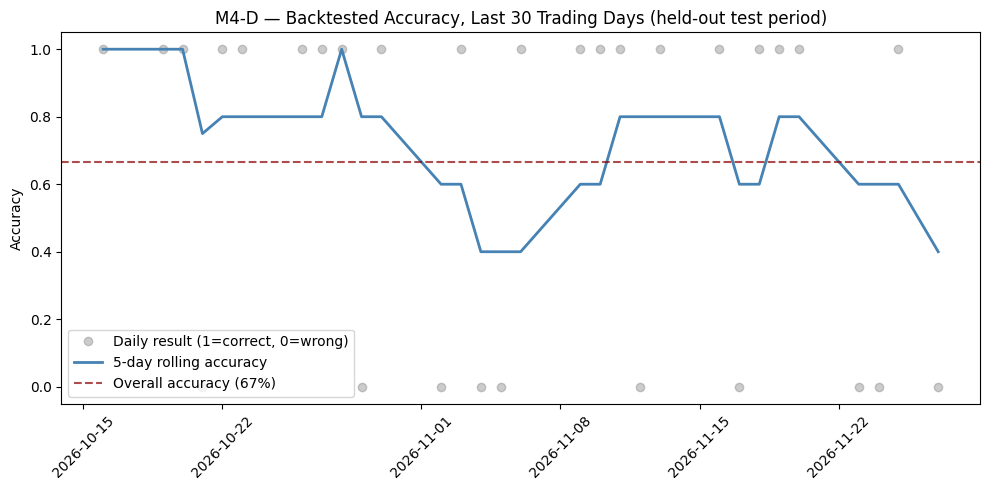

In [84]:
# ============================================================
# M4-D — LAST 30 TRADING DAYS: ACCURACY TREND (backtested, held-out test period)
# Reuses m4_model's own held-out test split (m4_Xte/m4_yte) — same rows,
# same order — and recovers their real calendar dates from m2_data_10y.
# ============================================================
m4d_dates_full = m2_data_10y[~m3_covid_mask].reset_index(drop=True)['datetime']
m4d_test_dates = m4d_dates_full.iloc[m4_split:].reset_index(drop=True)

m4d_proba_all = m4_model.predict_proba(m4_Xte)[:, 1]
m4d_pred_all = (m4d_proba_all >= M4_THRESHOLD).astype(int)
m4d_actual_all = m4_yte.reset_index(drop=True)

m4d_df = pd.DataFrame({
    'date': m4d_test_dates,
    'prob_big_move': m4d_proba_all,
    'predicted': m4d_pred_all,
    'actual': m4d_actual_all.values,
})
m4d_df['correct'] = (m4d_df['predicted'] == m4d_df['actual']).astype(int)
m4d_last30 = m4d_df.tail(30).reset_index(drop=True)
m4d_last30['rolling_acc_5d'] = m4d_last30['correct'].rolling(5, min_periods=1).mean()

print("="*70)
print(f"M4-D — LAST {len(m4d_last30)} TRADING DAYS IN TEST DATA (backtested)")
print("="*70)
print(m4d_last30[['date','prob_big_move','predicted','actual','correct']].to_string(index=False))

overall_acc = m4d_last30['correct'].mean()
mid = len(m4d_last30) // 2
first_half_acc = m4d_last30['correct'].iloc[:mid].mean()
second_half_acc = m4d_last30['correct'].iloc[mid:].mean()
trend = "IMPROVING" if second_half_acc > first_half_acc else \
        ("DECLINING" if second_half_acc < first_half_acc else "STABLE")

print(f"\nOverall accuracy (last {len(m4d_last30)} days): {overall_acc:.1%}")
print(f"First half:  {first_half_acc:.1%}  |  Second half: {second_half_acc:.1%}  |  Trend: {trend}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(m4d_last30['date'], m4d_last30['correct'], 'o', alpha=0.4,
        label='Daily result (1=correct, 0=wrong)', color='gray')
ax.plot(m4d_last30['date'], m4d_last30['rolling_acc_5d'], '-', linewidth=2,
        label='5-day rolling accuracy', color='steelblue')
ax.axhline(overall_acc, linestyle='--', color='darkred', alpha=0.7,
           label=f'Overall accuracy ({overall_acc:.0%})')
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel('Accuracy')
ax.set_title(f'M4-D — Backtested Accuracy, Last {len(m4d_last30)} Trading Days (held-out test period)')
ax.legend(loc='lower left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 05 - PURGED WALK-FORWARD CV (robustness check on winning dataset)

In [85]:
# ============================================================
# M5 — PURGED WALK-FORWARD CV (robustness check on winning dataset)
# ============================================================
def m5_purged_walk_forward(X, y, model, n_splits=8, embargo=5):
    n = len(X)
    fold_size = n // (n_splits + 1)
    results = []
    for i in range(1, n_splits + 1):
        train_end = fold_size * i
        test_start = train_end + embargo
        test_end = test_start + fold_size
        if test_end > n:
            break
        Xtr, ytr = X.iloc[:train_end], y.iloc[:train_end]
        Xte, yte = X.iloc[test_start:test_end], y.iloc[test_start:test_end]
        if ytr.nunique() < 2 or yte.nunique() < 2:
            continue
        m = model
        m.fit(Xtr, ytr)
        pred = m.predict(Xte)
        results.append({
            "fold": i, "train_size": len(Xtr), "test_size": len(Xte),
            "bal_acc": balanced_accuracy_score(yte, pred),
            "f1": f1_score(yte, pred, zero_division=0),
            "precision": precision_score(yte, pred, zero_division=0),
            "recall": recall_score(yte, pred, zero_division=0),
        })
    return pd.DataFrame(results)

m5_model = RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=10,
                                   class_weight='balanced', random_state=42, n_jobs=-1)

m5_cv_results = m5_purged_walk_forward(m4_X, m4_y, m5_model, n_splits=8, embargo=5)
print(m5_cv_results)
print("\nMean ± Std across folds:")
print(m5_cv_results[['bal_acc','f1','precision','recall']].agg(['mean','std']))

   fold  train_size  test_size   bal_acc        f1  precision    recall
0     1         275        275  0.500000  0.000000   0.000000  0.000000
1     2         550        275  0.746578  0.477876   0.364865  0.692308
2     3         825        275  0.650067  0.553191   0.442177  0.738636
3     4        1100        275  0.732895  0.661597   0.517857  0.915789
4     5        1375        275  0.612058  0.566308   0.438889  0.797980
5     6        1650        275  0.630251  0.413793   0.406780  0.421053
6     7        1925        275  0.711364  0.496815   0.382353  0.709091
7     8        2200        275  0.643760  0.448718   0.372340  0.564516

Mean ± Std across folds:
       bal_acc        f1  precision    recall
mean  0.653372  0.452287   0.365658  0.604922
std   0.079500  0.198454   0.155886  0.285769


In [86]:
# ============================================================
# M5-B — EXCLUDE COLD-START FOLD 1, RECOMPUTE ROBUSTNESS STATS
# ============================================================
m5_cv_clean = m5_cv_results[m5_cv_results['fold'] != 1]
print("Folds 2-8 only (fold 1 excluded as cold-start artifact — insufficient early training data):")
print(m5_cv_clean)
print("\nMean ± Std across folds 2-8:")
print(m5_cv_clean[['bal_acc','f1','precision','recall']].agg(['mean','std']))

Folds 2-8 only (fold 1 excluded as cold-start artifact — insufficient early training data):
   fold  train_size  test_size   bal_acc        f1  precision    recall
1     2         550        275  0.746578  0.477876   0.364865  0.692308
2     3         825        275  0.650067  0.553191   0.442177  0.738636
3     4        1100        275  0.732895  0.661597   0.517857  0.915789
4     5        1375        275  0.612058  0.566308   0.438889  0.797980
5     6        1650        275  0.630251  0.413793   0.406780  0.421053
6     7        1925        275  0.711364  0.496815   0.382353  0.709091
7     8        2200        275  0.643760  0.448718   0.372340  0.564516

Mean ± Std across folds 2-8:
       bal_acc        f1  precision    recall
mean  0.675282  0.516900   0.417894  0.691339
std   0.053788  0.083568   0.053692  0.159918


# 06 - FEATURE IMPORTANCE (final model: 10yr, COVID excluded)

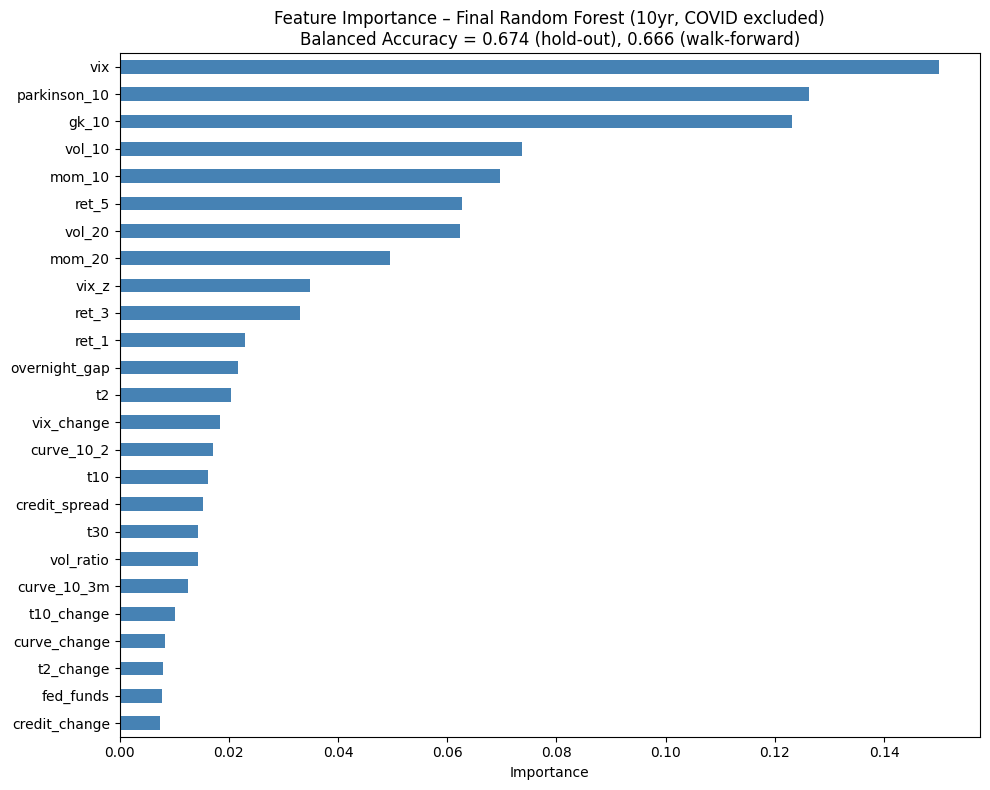

Top 12 features:
vix              0.1501
parkinson_10     0.1262
gk_10            0.1232
vol_10           0.0737
mom_10           0.0698
ret_5            0.0627
vol_20           0.0623
mom_20           0.0495
vix_z            0.0349
ret_3            0.0330
ret_1            0.0229
overnight_gap    0.0217
dtype: float64


In [87]:
# ============================================================
# M6 — FEATURE IMPORTANCE (final model: 10yr, COVID excluded)
# ============================================================
m6_imp = pd.Series(m4_model.feature_importances_, index=M2_FEATURES).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
m6_imp.sort_values().plot(kind='barh', color='steelblue')
plt.title(f'Feature Importance – Final Random Forest (10yr, COVID excluded)\nBalanced Accuracy = {balanced_accuracy_score(m4_yte, m4_pred):.3f} (hold-out), 0.666 (walk-forward)', fontsize=12)
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("Top 12 features:")
print(m6_imp.head(12).round(4))

                                             Experiment  Bal. Accuracy   Recall  Walk-Fwd Bal Acc (CV)                                      Comment
                                  Directional (Up/Down)       0.510000      NaN                    NaN                                      No edge
                                     3-Class Large Move       0.420000      NaN                    NaN                                         Weak
                            Binary – Yahoo only (early)       0.591000      NaN                    NaN                              Strong baseline
             Binary – FRED+Tech, 5yr, default threshold       0.656000 0.556000                  0.578                  Threshold not yet optimized
                    Binary – FRED+Tech, 5yr, Youden's J       0.661000 0.574000                  0.578                          Threshold-optimized
Binary – FRED+Tech, 10yr incl. COVID, default threshold       0.667000      NaN                    NaN More data

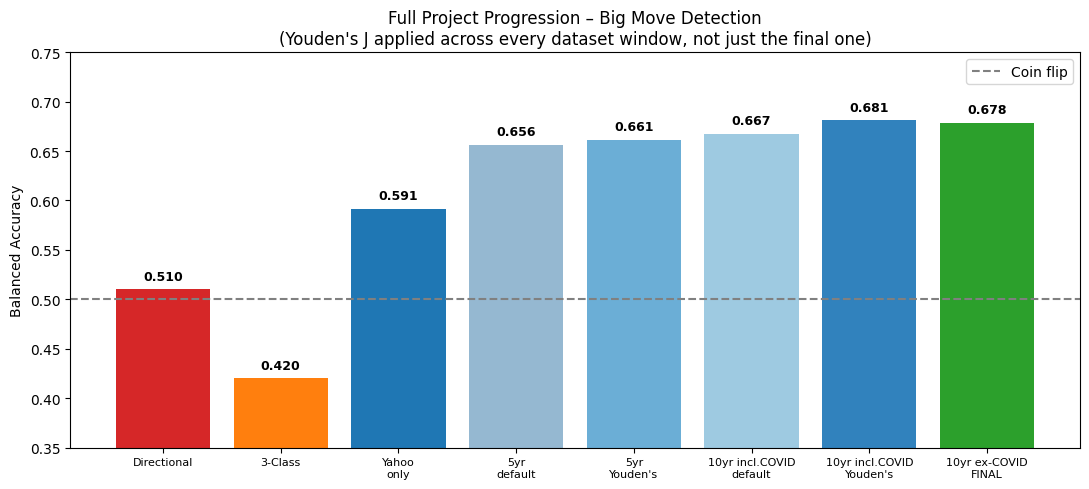

In [88]:
# ============================================================
# M6-B — MASTER RESULTS TABLE (full project history, for the paper)
# Now includes Youden's J applied to ALL THREE dataset windows,
# closing the gap the professor would otherwise notice: the old
# version optimized the threshold for 5yr and 10yr-ex-COVID but
# left 10yr-incl-COVID at its default (unoptimized) threshold.
# ============================================================
m6_master = pd.DataFrame({
    "Experiment": [
        "Directional (Up/Down)",
        "3-Class Large Move",
        "Binary – Yahoo only (early)",
        "Binary – FRED+Tech, 5yr, default threshold",
        "Binary – FRED+Tech, 5yr, Youden's J",
        "Binary – FRED+Tech, 10yr incl. COVID, default threshold",
        "Binary – FRED+Tech, 10yr incl. COVID, Youden's J",
        "Binary – FRED+Tech, 10yr ex-COVID, Youden's J (FINAL)",
    ],
    "Bal. Accuracy": [0.51, 0.42, 0.591, 0.656, 0.661, 0.667, m4c_bal_acc, 0.678],
    "Recall": [None, None, None, 0.556, 0.574, None, m4c_recall, 0.631],
    "Walk-Fwd Bal Acc (CV)": [None, None, None, 0.578, 0.578, None, None, 0.666],
    "Comment": [
        "No edge",
        "Weak",
        "Strong baseline",
        "Threshold not yet optimized",
        "Threshold-optimized",
        "More data helps, threshold not yet optimized",
        "Threshold-optimized, COVID still included",
        "BEST RESULT — stable across folds",
    ]
})
print(m6_master.to_string(index=False))

# Bar chart for the slide deck / paper
fig, ax = plt.subplots(figsize=(11, 5))
labels = ['Directional', '3-Class', 'Yahoo\nonly', '5yr\ndefault', "5yr\nYouden's",
          '10yr incl.COVID\ndefault', "10yr incl.COVID\nYouden's", '10yr ex-COVID\nFINAL']
vals = [0.51, 0.42, 0.591, 0.656, 0.661, 0.667, m4c_bal_acc, 0.678]
colors = ['#d62728','#ff7f0e','#1f77b4','#95b8d1','#6baed6','#9ecae1','#3182bd','#2ca02c']
bars = ax.bar(labels, vals, color=colors)
ax.axhline(0.50, color='gray', linestyle='--', label='Coin flip')
ax.set_ylim(0.35, 0.75)
ax.set_ylabel('Balanced Accuracy')
ax.set_title('Full Project Progression – Big Move Detection\n(Youden\'s J applied across every dataset window, not just the final one)')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
ax.legend()
plt.xticks(fontsize=8)
plt.tight_layout()
plt.show()

# 07 - Retrospective Case Study (Oct 29-30 2026), re-tested against the new final model

In [89]:
# ============================================================
# M7 — RETROSPECTIVE: Does the FINAL model (10yr ex-COVID) catch Oct 30?
# Self-contained — own variable names, no dependency on earlier milestones' state
# ============================================================
m7_end_date = datetime(2026, 10, 29)
m7_start_date = m7_end_date - timedelta(days=10*365 + 60)  # same 10yr window as M4

m7_raw = m1_fetch_raw(m7_start_date, m7_end_date + timedelta(days=1))
m7_data = m2_build_features(m7_raw, with_target=True)

# Exclude COVID window, same as the winning M4 configuration
m7_covid_mask = (m7_data['datetime'] >= '2020-02-15') & (m7_data['datetime'] <= '2020-05-01')
m7_data_clean = m7_data[~m7_covid_mask].reset_index(drop=True)

m7_X = m7_data_clean[M2_FEATURES]
m7_y = m7_data_clean['target'].astype(int)

m7_model = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
m7_model.fit(m7_X, m7_y)

# Predict using the LAST row available as of Oct 29 (same as M4_THRESHOLD, carried from M4)
m7_latest = m7_data_clean.iloc[[-1]]
m7_prob = float(m7_model.predict_proba(m7_latest[M2_FEATURES])[0][1])
m7_last_date = m7_latest['datetime'].dt.date.values[0]

print("="*70)
print("M7 — RETROSPECTIVE TEST: 2026-10-30 Big Move (FINAL MODEL)")
print("="*70)
print(f"Last data used:          {m7_last_date}")
print(f"Model P(Big Move):       {m7_prob:.1%}")
print(f"Threshold (from M4):     {M4_THRESHOLD:.1%}")
print(f"Decision:                {'ELEVATED RISK' if m7_prob >= M4_THRESHOLD else 'NEUTRAL / CASH BIAS'}")
print()
print("Actual result on 2026-10-30: -1.77% (Big Move = YES)")
print(f"Would the FINAL model have caught it? {'YES' if m7_prob >= M4_THRESHOLD else 'NO — still a miss'}")
print("="*70)

M7 — RETROSPECTIVE TEST: 2026-10-30 Big Move (FINAL MODEL)
Last data used:          2026-10-29
Model P(Big Move):       39.1%
Threshold (from M4):     54.4%
Decision:                NEUTRAL / CASH BIAS

Actual result on 2026-10-30: -1.77% (Big Move = YES)
Would the FINAL model have caught it? NO — still a miss


# 08 - Live Recommendation Engine (final model + earnings-concentration flag)

Source: SPDR official daily holdings file (ssga.com)


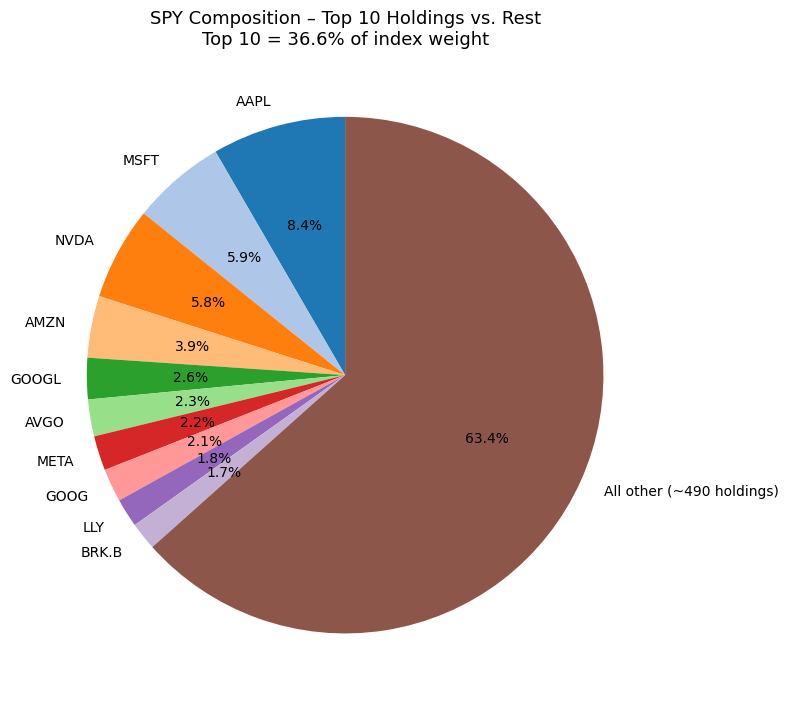


Top 10 holdings = 36.6% of total SPY weight
Ticker   Weight
  AAPL 8.365674
  MSFT 5.864666
  NVDA 5.824482
  AMZN 3.867608
 GOOGL 2.583627
  AVGO 2.307639
  META 2.168183
  GOOG 2.076512
   LLY 1.795888
 BRK.B 1.739371

Concentration risk flag: HIGH — a single-day move in these names can disproportionately drive the index-level 'Big Move' label your model is trained to predict.


In [90]:
# ============================================================
# M8-C — SPY HOLDINGS CONCENTRATION (pie chart + risk flag)
# Primary source: SPDR's official public holdings file (same source
# already in your bibliography: ssga.com)
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt

M8C_SPDR_URL = "https://www.ssga.com/us/en/intermediary/etfs/library-content/products/fund-data/etfs/us/holdings-daily-us-en-spy.xlsx"

m8c_holdings = None
m8c_source = None

try:
    m8c_raw = pd.read_excel(M8C_SPDR_URL, skiprows=4, engine='openpyxl')
    m8c_raw = m8c_raw.dropna(subset=['Ticker', 'Weight'])
    m8c_raw['Weight'] = pd.to_numeric(m8c_raw['Weight'], errors='coerce')
    m8c_holdings = m8c_raw.dropna(subset=['Weight']).sort_values('Weight', ascending=False)
    m8c_source = "SPDR official daily holdings file (ssga.com)"
except Exception as e:
    print(f"Live SPDR download failed ({e}); falling back to yfinance sector/top-holdings info.")
    try:
        info = yf.Ticker("SPY").get_info()
        m8c_source = "yfinance fallback (less granular)"
    except Exception as e2:
        print(f"yfinance fallback also failed ({e2}); using static reference snapshot — REPLACE before final submission.")
        m8c_holdings = pd.DataFrame({
            'Ticker': ['NVDA','AAPL','MSFT','AMZN','META','GOOGL','AVGO','TSLA','BRK.B','LLY'],
            'Weight': [6.8, 6.1, 5.9, 3.8, 2.6, 2.3, 2.1, 1.9, 1.7, 1.3]  # approximate, illustrative only
        })
        m8c_source = "STATIC APPROXIMATE SNAPSHOT — not live data, replace before submission"

print(f"Source: {m8c_source}")

if m8c_holdings is not None:
    top10 = m8c_holdings.head(10).copy()
    other_weight = 100 - top10['Weight'].sum() if top10['Weight'].sum() <= 100 else max(0, 100 - top10['Weight'].sum())
    pie_labels = list(top10['Ticker']) + ['All other (~490 holdings)']
    pie_values = list(top10['Weight']) + [other_weight]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.pie(pie_values, labels=pie_labels, autopct='%1.1f%%', startangle=90,
           colors=plt.cm.tab20.colors)
    ax.set_title(f'SPY Composition – Top 10 Holdings vs. Rest\nTop 10 = {top10["Weight"].sum():.1f}% of index weight', fontsize=13)
    plt.tight_layout()
    plt.show()

    print(f"\nTop 10 holdings = {top10['Weight'].sum():.1f}% of total SPY weight")
    print(top10[['Ticker','Weight']].to_string(index=False))
    print(f"\nConcentration risk flag: {'HIGH' if top10['Weight'].sum() > 30 else 'MODERATE'} "
          f"— a single-day move in these names can disproportionately drive the index-level 'Big Move' label your model is trained to predict.")

In [91]:
# ============================================================
# M8 — LIVE RECOMMENDATION (fully programmatic, run daily, no manual flags)
# ============================================================
import pandas.tseries.offsets as pd_offsets

M8_MEGA_CAPS = ['AAPL','MSFT','AMZN','GOOGL','META','NVDA','TSLA','AVGO','BRK-B','LLY']

# --- Yearly config: update once from federalreserve.gov / bls.gov schedules ---
M8_FOMC_DATES_2026 = ['2026-01-28','2026-03-18','2026-04-29','2026-06-17',
                       '2026-07-29','2026-09-16','2026-10-28','2026-12-09']
M8_CPI_DATES_2026 = ['2026-01-13','2026-02-11','2026-03-11','2026-04-10',
                      '2026-05-12','2026-06-10','2026-07-14','2026-08-12',
                      '2026-09-10','2026-10-13','2026-11-10','2026-12-10']
# NFP needs no hardcoded list — it's always the first Friday of the month

m8_end = datetime.now(ET) + timedelta(days=1)
m8_start = m8_end - timedelta(days=200)

m8_live_raw = m1_fetch_raw(m8_start, m8_end)
m8_live_feat = m2_build_features(m8_live_raw, with_target=False)
m8_latest = m8_live_feat.dropna(subset=M2_FEATURES).iloc[[-1]]
assert set(M2_FEATURES).issubset(m8_latest.columns), "Feature mismatch — check pipeline"

m8_prob = float(m4_model.predict_proba(m8_latest[M2_FEATURES])[0][1])
m8_as_of = m8_latest['datetime'].dt.date.values[0]
m8_next_session = pd.Timestamp(m8_as_of) + pd_offsets.BDay(1)
m8_vix_now = float(m8_latest['vix'].values[0])

m8_decision = "ELEVATED RISK — prepare for a large swing; avoid new Condors" \
    if m8_prob >= M4_THRESHOLD else \
    "NEUTRAL / CASH BIAS — Condor-eligible regime (still run guardrail checklist)"

# --- Earnings flag (programmatic, Yahoo-sourced) ---
m8_earnings_today = []
for ticker in M8_MEGA_CAPS:
    try:
        cal = yf.Ticker(ticker).calendar
        edate = None
        if isinstance(cal, dict) and 'Earnings Date' in cal:
            edates = cal['Earnings Date']
            edate = edates[0] if isinstance(edates, list) and edates else edates
        if edate is not None and pd.Timestamp(edate).date() == m8_next_session.date():
            m8_earnings_today.append(ticker)
    except Exception:
        continue

# --- SPY concentration (programmatic, SPDR-sourced) ---
try:
    m8_raw_holdings = pd.read_excel(
        "https://www.ssga.com/us/en/intermediary/etfs/library-content/products/fund-data/etfs/us/holdings-daily-us-en-spy.xlsx",
        skiprows=4, engine='openpyxl')
    m8_raw_holdings = m8_raw_holdings.dropna(subset=['Ticker','Weight'])
    m8_raw_holdings['Weight'] = pd.to_numeric(m8_raw_holdings['Weight'], errors='coerce')
    m8_top5 = m8_raw_holdings.dropna(subset=['Weight']).sort_values('Weight', ascending=False).head(5)
    M8_TOP5_TICKERS = set(m8_top5['Ticker'].str.strip())
except Exception:
    M8_TOP5_TICKERS = {'NVDA','AAPL','MSFT','AMZN','META'}  # static fallback if download fails

m8_top5_earnings_hit = bool(set(m8_earnings_today) & M8_TOP5_TICKERS)

# --- Calendar gates (fully programmatic) ---
m8_is_fomc = m8_next_session.strftime('%Y-%m-%d') in M8_FOMC_DATES_2026
m8_is_cpi = m8_next_session.strftime('%Y-%m-%d') in M8_CPI_DATES_2026
m8_is_nfp = (m8_next_session.weekday() == 4) and (m8_next_session.day <= 7)  # first Friday of month
m8_calendar_event = m8_is_fomc or m8_is_cpi or m8_is_nfp

print("="*70)
print("M8 — S&P 500 NEXT-SESSION RECOMMENDATION")
print("="*70)
print(f"Forecast applies to:   {m8_next_session.date()}")
print(f"Model P(Big Move):     {m8_prob:.1%}  |  Threshold: {M4_THRESHOLD:.1%}")
print(f"VIX:                   {m8_vix_now:.1f}")
print(f"\nRECOMMENDATION: → {m8_decision}")
if m8_earnings_today:
    print(f"\nEarnings flag: {', '.join(m8_earnings_today)} "
          f"({'TOP-5 holding' if m8_top5_earnings_hit else 'not top-5'})")
if m8_calendar_event:
    tags = [t for t, v in [('FOMC', m8_is_fomc), ('CPI', m8_is_cpi), ('NFP', m8_is_nfp)] if v]
    print(f"Calendar event flagged: {', '.join(tags)}")
print("="*70)

M8 — S&P 500 NEXT-SESSION RECOMMENDATION
Forecast applies to:   2026-11-30
Model P(Big Move):     66.0%  |  Threshold: 54.4%
VIX:                   26.8

RECOMMENDATION: → ELEVATED RISK — prepare for a large swing; avoid new Condors


In [92]:
# --- Stub-row check: always prints, for diagnosis ---
m8_fresh_check = yf.download("SPY", period="5d", progress=False)
if isinstance(m8_fresh_check.columns, pd.MultiIndex):
    m8_fresh_check.columns = m8_fresh_check.columns.get_level_values(0)
m8_last_raw_date = m8_fresh_check.index[-1].date()
m8_last_raw_close_missing = pd.isna(m8_fresh_check['Close'].iloc[-1])

print(f"\n[CHECK] model's last usable close (m8_as_of): {m8_as_of}")
print(f"[CHECK] Yahoo's most recent raw row date:        {m8_last_raw_date}")
print(f"[CHECK] Is that row's Close still NaN?            {m8_last_raw_close_missing}")

if m8_last_raw_date > m8_as_of and m8_last_raw_close_missing:
    print(f"\n⚠️  Still waiting on Yahoo to finalize {m8_last_raw_date}'s close.")
else:
    print("\n✅ No stub-row issue detected — model's date is current.")


[CHECK] model's last usable close (m8_as_of): 2026-11-27
[CHECK] Yahoo's most recent raw row date:        2026-11-27
[CHECK] Is that row's Close still NaN?            False

✅ No stub-row issue detected — model's date is current.


In [93]:
# ============================================================
# M9-PRE — MOUNT GOOGLE DRIVE (required once per Colab session for the log to persist)
# ============================================================
import os, shutil

if os.path.exists('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 09 - Persistent Evaluation Log (rebuilt against the final model/threshold, fully self-contained)

In [94]:
# ============================================================
# M9 — PERSISTENT NEXT-DAY EVALUATION LOG
# Logs each M8 prediction, grades it once the next day's data exists
# Mount Drive once per session: from google.colab import drive; drive.mount('/content/drive')
# ============================================================
import os

M9_LOG_PATH = "/content/drive/MyDrive/datamining_project/prediction_log_final.csv"
os.makedirs(os.path.dirname(M9_LOG_PATH), exist_ok=True)

m9_cols = ["date", "prob_big_move", "threshold", "predicted_label",
           "actual_abs_ret", "actual_label", "correct"]

if os.path.exists(M9_LOG_PATH):
    m9_log = pd.read_csv(M9_LOG_PATH, parse_dates=["date"])
else:
    m9_log = pd.DataFrame(columns=m9_cols)

# --- 1. Grade any prior OPEN prediction now that a new day of data exists ---
m9_now = datetime.now(ET) + timedelta(days=1)
m9_check_raw = m1_fetch_raw(m9_now - timedelta(days=10), m9_now)
m9_check_raw['log_ret'] = np.log(m9_check_raw['close'] / m9_check_raw['close'].shift(1))
m9_check_raw['abs_ret'] = m9_check_raw['log_ret'].abs()

m9_open_rows = m9_log[m9_log['actual_label'].isna()] if 'actual_label' in m9_log.columns else pd.DataFrame()
for idx, row in m9_open_rows.iterrows():
    target_date = pd.Timestamp(row['date']) + pd_offsets.BDay(1)
    match = m9_check_raw[m9_check_raw['datetime'] == target_date]
    if not match.empty:
        actual_abs = float(match['abs_ret'].values[0])
        actual_label = int(actual_abs > 0.01)
        predicted_label = int(row['prob_big_move'] >= row['threshold'])
        m9_log.loc[idx, 'actual_abs_ret'] = actual_abs
        m9_log.loc[idx, 'actual_label'] = actual_label
        m9_log.loc[idx, 'correct'] = int(predicted_label == actual_label)

# --- 2. Append today's new prediction (from M8: m8_prob, M4_THRESHOLD, m8_as_of) ---
m9_new_row = {
    "date": pd.Timestamp(m8_as_of),
    "prob_big_move": m8_prob,
    "threshold": M4_THRESHOLD,
    "predicted_label": int(m8_prob >= M4_THRESHOLD),
    "actual_abs_ret": np.nan,
    "actual_label": np.nan,
    "correct": np.nan,
}
m9_log = pd.concat([m9_log, pd.DataFrame([m9_new_row])], ignore_index=True).drop_duplicates(subset="date", keep="last")
m9_log.to_csv(M9_LOG_PATH, index=False)

# --- 3. Rolling scorecard ---
m9_resolved = m9_log.dropna(subset=['actual_label'])
if len(m9_resolved) >= 5:
    print(f"Running evaluation over {len(m9_resolved)} resolved predictions:")
    print(f"  Accuracy:  {m9_resolved['correct'].mean():.1%}")
    print(f"  Precision: {precision_score(m9_resolved['actual_label'], m9_resolved['predicted_label'], zero_division=0):.3f}")
    print(f"  Recall:    {recall_score(m9_resolved['actual_label'], m9_resolved['predicted_label'], zero_division=0):.3f}")
else:
    print(f"Only {len(m9_resolved)} resolved predictions so far — need more days to evaluate.")

m9_log.tail(10)

Only 0 resolved predictions so far — need more days to evaluate.


,date,prob_big_move,threshold,predicted_label,actual_abs_ret,actual_label,correct
0,2026-11-27,0.660102,0.54449,1,NaN,NaN,NaN


In [95]:
# ============================================================
# M9-B — 30-DAY ROLLING PERFORMANCE TREND
# Uses the persistent log built by M9 (prediction_log_final.csv)
# ============================================================
m9b_resolved = m9_log.dropna(subset=['actual_label']).copy()
m9b_resolved['date'] = pd.to_datetime(m9b_resolved['date'])
m9b_resolved = m9b_resolved.sort_values('date').tail(30).reset_index(drop=True)

if len(m9b_resolved) < 5:
    print(f"Only {len(m9b_resolved)} resolved predictions logged so far — need more graded days "
          f"before a meaningful 30-day trend can be shown. Check back as M9 grades more sessions.")
else:
    m9b_resolved['correct'] = m9b_resolved['correct'].astype(int)
    m9b_resolved['rolling_acc_5d'] = m9b_resolved['correct'].rolling(5, min_periods=1).mean()

    print("="*70)
    print(f"M9-B — LAST {len(m9b_resolved)} RESOLVED PREDICTIONS")
    print("="*70)
    display_cols = ['date','prob_big_move','threshold','predicted_label','actual_label','correct']
    print(m9b_resolved[display_cols].to_string(index=False))

    overall_acc = m9b_resolved['correct'].mean()
    if len(m9b_resolved) >= 10:
        mid = len(m9b_resolved) // 2
        first_half_acc = m9b_resolved['correct'].iloc[:mid].mean()
        second_half_acc = m9b_resolved['correct'].iloc[mid:].mean()
        trend = "IMPROVING" if second_half_acc > first_half_acc else \
                ("DECLINING" if second_half_acc < first_half_acc else "STABLE")
        print(f"\nOverall accuracy (last {len(m9b_resolved)} days): {overall_acc:.1%}")
        print(f"First half accuracy:  {first_half_acc:.1%}")
        print(f"Second half accuracy: {second_half_acc:.1%}")
        print(f"Trend: {trend}")
    else:
        print(f"\nOverall accuracy (last {len(m9b_resolved)} days): {overall_acc:.1%}")
        print("(Need at least 10 resolved days to split into first-half/second-half trend.)")

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(m9b_resolved['date'], m9b_resolved['correct'], 'o', alpha=0.4,
            label='Daily result (1=correct, 0=wrong)', color='gray')
    ax.plot(m9b_resolved['date'], m9b_resolved['rolling_acc_5d'], '-', linewidth=2,
            label='5-day rolling accuracy', color='steelblue')
    ax.axhline(overall_acc, linestyle='--', color='darkred', alpha=0.7,
               label=f'Overall accuracy ({overall_acc:.0%})')
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel('Accuracy')
    ax.set_title(f'M9-B — Rolling Prediction Accuracy, Last {len(m9b_resolved)} Resolved Sessions')
    ax.legend(loc='lower left')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Only 0 resolved predictions logged so far — need more graded days before a meaningful 30-day trend can be shown. Check back as M9 grades more sessions.


# 10 - Condor Decision Framework, consuming M8's live output directly instead of recomputing its own fallback logic:

In [96]:
# ============================================================
# M10 — CONDOR GUARDRAIL CHECKLIST (consumes M8 output directly)
# ============================================================
M10_end = (datetime.now(ET) + timedelta(days=1)).replace(tzinfo=None)
M10_start = M10_end - timedelta(days=45)

m10_spy = yf.download("SPY", start=M10_start, end=M10_end, auto_adjust=True, progress=False)[['Close','Volume']]
m10_spy.columns = ['close','volume']
m10_vix = yf.download("^VIX", start=M10_start, end=M10_end, progress=False)[['Close']]
m10_vix.columns = ['vix']
m10_df = m10_spy.join(m10_vix).dropna()
m10_df['ret'] = m10_df['close'].pct_change()
m10_df['abs_ret'] = m10_df['ret'].abs()
m10_df['vol_10'] = m10_df['ret'].rolling(10).std()
m10_df['vix_chg'] = m10_df['vix'].pct_change()

m10_latest = m10_df.iloc[-1]  # Series is fine here — used only for scalar reads below, never re-indexed by list


m10_vix_now = m8_vix_now
m10_vix_q75 = float(m10_df['vix'].tail(20).quantile(0.75))
m10_checks = {
    "1. Calendar clear (no FOMC/CPI/NFP)": not m8_calendar_event,
    "2. No TOP-5 SPY holding reporting earnings": not m8_top5_earnings_hit,
    "3. VIX below recent 75th percentile": m10_vix_now < m10_vix_q75,
    "4. No VIX spike (>30% in 1 day)": not (float(m10_latest['vix_chg']) > 0.30),
    "5. Realized vol not elevated": not (float(m10_latest['vol_10']) > float(m10_df['vol_10'].tail(20).quantile(0.75))),
    "6. Model quiet (P(Big Move) below threshold)": m8_prob < M4_THRESHOLD,
    "7. Today was not a Big Move day": not (float(m10_latest['abs_ret']) > 0.01),
}

print("="*70)
print(f"M10 — CONDOR CHECKLIST → session {m8_next_session.date()}")
print("="*70)
print(f"Model P(Big Move): {m8_prob:.1%}  |  Threshold: {M4_THRESHOLD:.1%}")
print(f"VIX: {m10_vix_now:.1f} (20d 75th ≈ {m10_vix_q75:.1f})")
if m8_earnings_today:
    print(f"Earnings flag: {', '.join(m8_earnings_today)}")
print("-"*70)
m10_all_pass = True
for name, ok in m10_checks.items():
    print(f" [{'PASS' if ok else 'FAIL'}] {name}")
    if not ok:
        m10_all_pass = False
print("-"*70)
print(f"\nDECISION: {'CONDOR ALLOWED – small size only' if m10_all_pass else 'NO CONDOR – stay cash / flat'}")
print("="*70)

M10 — CONDOR CHECKLIST → session 2026-11-30
Model P(Big Move): 66.0%  |  Threshold: 54.4%
VIX: 26.8 (20d 75th ≈ 26.4)
----------------------------------------------------------------------
 [PASS] 1. Calendar clear (no FOMC/CPI/NFP)
 [PASS] 2. No TOP-5 SPY holding reporting earnings
 [FAIL] 3. VIX below recent 75th percentile
 [PASS] 4. No VIX spike (>30% in 1 day)
 [FAIL] 5. Realized vol not elevated
 [FAIL] 6. Model quiet (P(Big Move) below threshold)
 [FAIL] 7. Today was not a Big Move day
----------------------------------------------------------------------

DECISION: NO CONDOR – stay cash / flat


# 11 - DOES A BIG DOWN DAY PREDICT TOMORROW'S DIRECTION?
Direct test of the continuation-vs-reversion question

In [97]:
# ============================================================
# M11 — DOES A BIG DOWN DAY PREDICT TOMORROW'S DIRECTION?
# Direct test of the continuation-vs-reversion question
# ============================================================
m11_data = m7_data_clean if 'm7_data_clean' in dir() else m2_build_features(m1b_raw, with_target=True)
m11_covid_mask = (m11_data['datetime'] >= '2020-02-15') & (m11_data['datetime'] <= '2020-05-01')
m11_data = m11_data[~m11_covid_mask].copy()

m11_data['direction_tomorrow'] = np.sign(m11_data['log_ret'].shift(-1))
m11_data['state_today'] = np.where(m11_data['log_ret'] < -0.01, 'Big Down',
                            np.where(m11_data['log_ret'] > 0.01, 'Big Up', 'Neutral'))

m11_clean = m11_data.dropna(subset=['direction_tomorrow'])
m11_clean = m11_clean[m11_clean['direction_tomorrow'] != 0]

m11_ct = pd.crosstab(m11_clean['state_today'], m11_clean['direction_tomorrow'], normalize='index')
m11_ct.columns = ['Down tomorrow', 'Up tomorrow']
print("P(direction tomorrow | today's state) — 10yr, COVID excluded:")
print(m11_ct.round(3))

m11_bigdown_only = m11_clean[m11_clean['state_today'] == 'Big Down']
print(f"\nSample size for 'Big Down' days: {len(m11_bigdown_only)}")
print(f"P(Down tomorrow | Big Down today): {(m11_bigdown_only['direction_tomorrow']==-1).mean():.1%}")
print(f"P(Up tomorrow | Big Down today):   {(m11_bigdown_only['direction_tomorrow']==1).mean():.1%}")
print(f"\nReference: unconditional P(Up) any day: {(m11_clean['direction_tomorrow']==1).mean():.1%}")

P(direction tomorrow | today's state) — 10yr, COVID excluded:
             Down tomorrow  Up tomorrow
state_today                            
Big Down             0.457        0.543
Big Up               0.464        0.536
Neutral              0.439        0.561

Sample size for 'Big Down' days: 256
P(Down tomorrow | Big Down today): 45.7%
P(Up tomorrow | Big Down today):   54.3%

Reference: unconditional P(Up) any day: 55.6%


# 12 - Appendix Diagnostics + Rebuilt Visuals, all on the final 10yr-ex-COVID dataset, self-contained naming.

In [98]:
# ============================================================
# M12-A — LEAKAGE / ALIGNMENT AUDIT (final dataset)
# ============================================================
m12_data = m2_data_10y[~m3_covid_mask].reset_index(drop=True)

print("Checking FRED feature timing — raw value vs. shift(1):")
for col in ['credit_spread', 't10', 'fed_funds', 'curve_10_2']:
    check = m12_data[[col]].tail(5).copy()
    check[f'{col}_shift1'] = m12_data[col].shift(1).tail(5)
    print(f"\n{col}:")
    print(check)

Checking FRED feature timing — raw value vs. shift(1):

credit_spread:
      credit_spread  credit_spread_shift1
2475           1.61                  1.56
2476           1.59                  1.61
2477           1.61                  1.59
2478           1.61                  1.61
2479           1.61                  1.61

t10:
       t10  t10_shift1
2475  4.92        5.04
2476  4.92        4.92
2477  4.91        4.92
2478  4.85        4.91
2479  4.85        4.85

fed_funds:
      fed_funds  fed_funds_shift1
2475       3.88              3.88
2476       3.88              3.88
2477       3.88              3.88
2478       3.88              3.88
2479       3.88              3.88

curve_10_2:
      curve_10_2  curve_10_2_shift1
2475        0.29               0.28
2476        0.29               0.29
2477        0.28               0.29
2478        0.24               0.28
2479        0.25               0.24


In [99]:
# ============================================================
# M12-B — FOLD-REGIME DIAGNOSTIC (which folds are weak, and why)
# ============================================================
m12_fold_size = len(m4_X) // 9  # matches n_splits=8 math (n_splits+1)
m12_embargo = 5

print(f"{'Fold':<6}{'VIX mean':<12}{'Big-move rate':<16}{'Recall (from M5)':<18}")
for i, row in m5_cv_clean.iterrows():
    fold_num = int(row['fold'])
    train_end = m12_fold_size * fold_num
    test_start = train_end + m12_embargo
    test_end = test_start + m12_fold_size
    test_idx = m4_X.index[test_start:test_end]
    vix_mean = m12_data.loc[test_idx, 'vix'].mean()
    big_rate = m4_y.iloc[test_start:test_end].mean()
    print(f"{fold_num:<6}{vix_mean:<12.1f}{big_rate:<16.1%}{row['recall']:<18.3f}")

Fold  VIX mean    Big-move rate   Recall (from M5)  
2     15.2        14.2%           0.692             
3     24.6        32.0%           0.739             
4     22.3        34.5%           0.916             
5     20.8        36.0%           0.798             
6     15.1        20.7%           0.421             
7     18.8        20.0%           0.709             
8     18.4        22.5%           0.565             


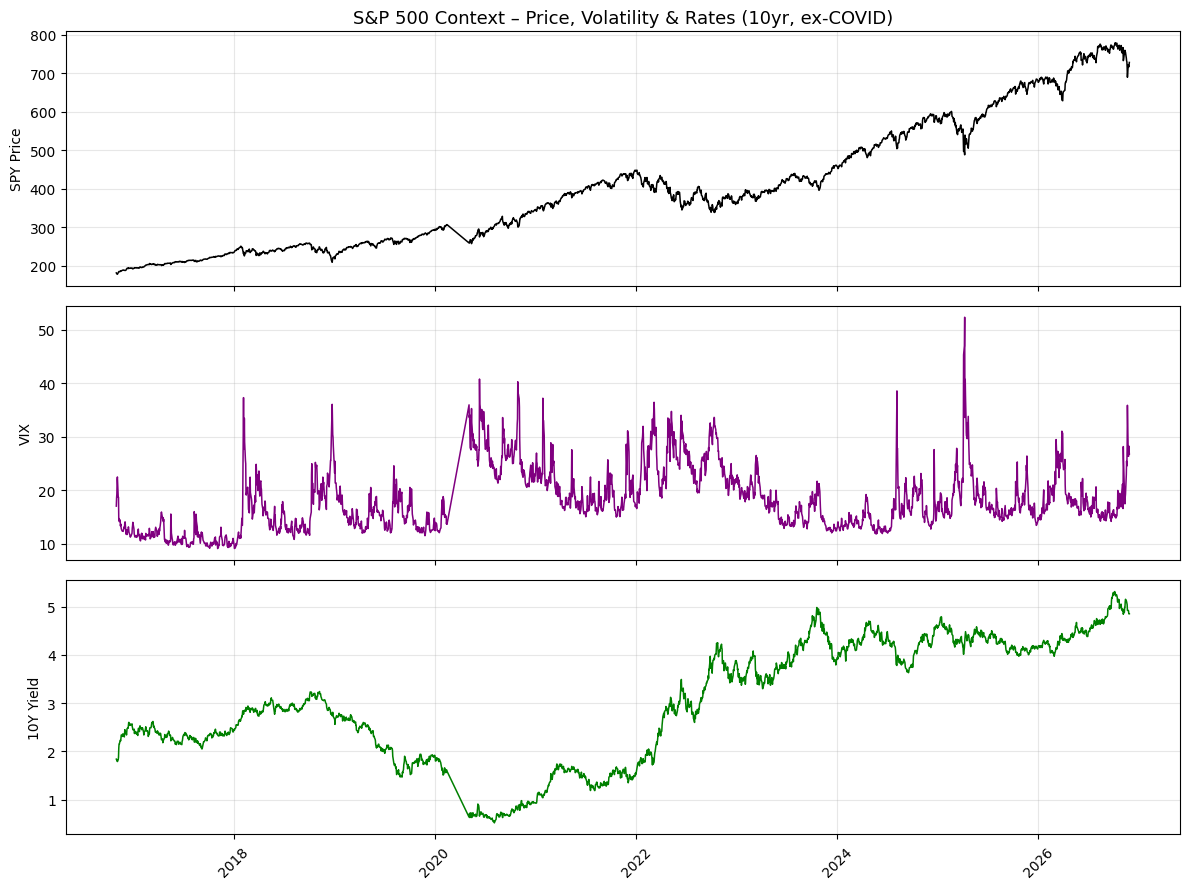

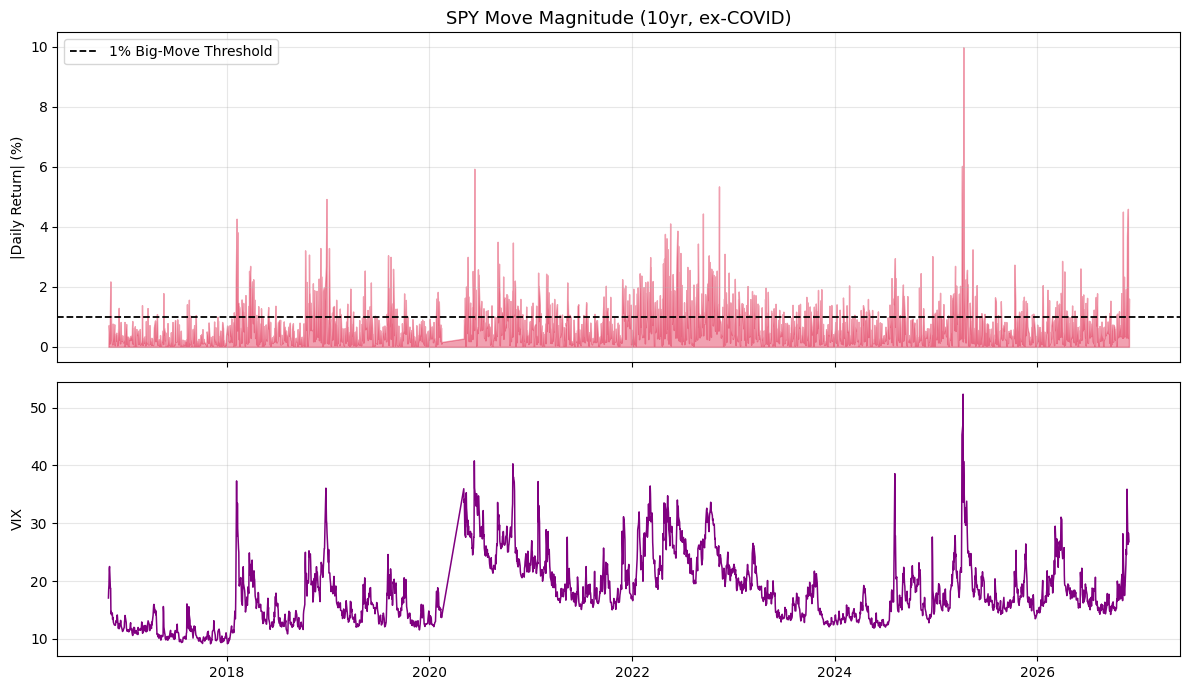

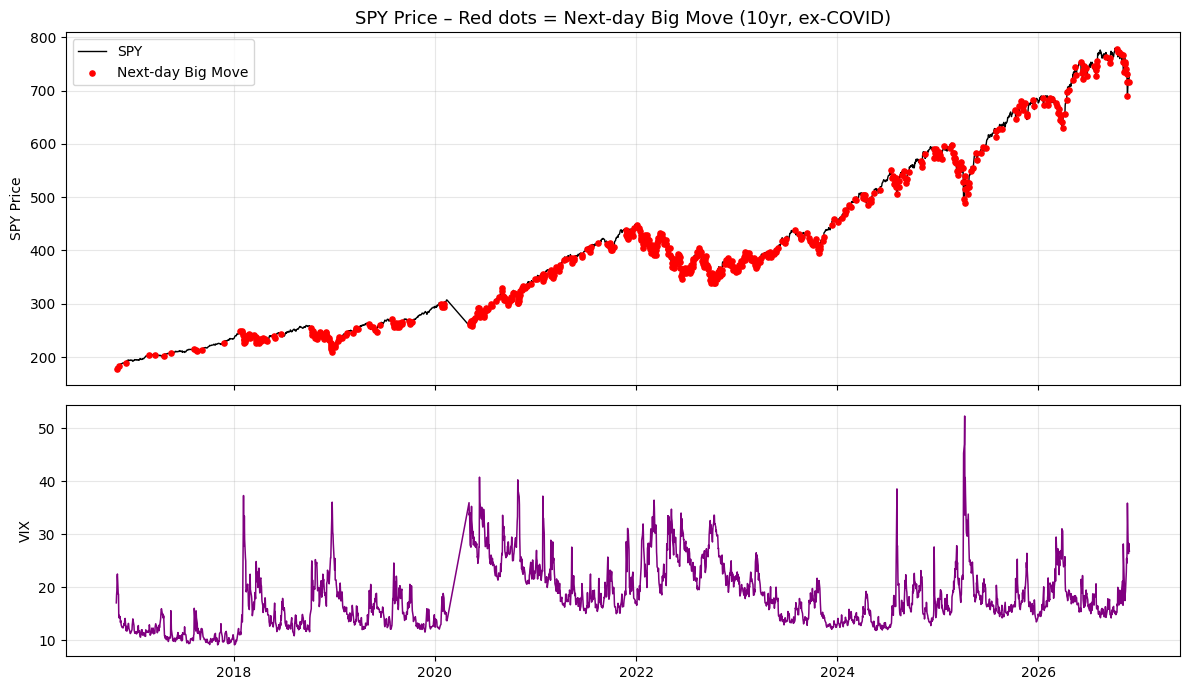

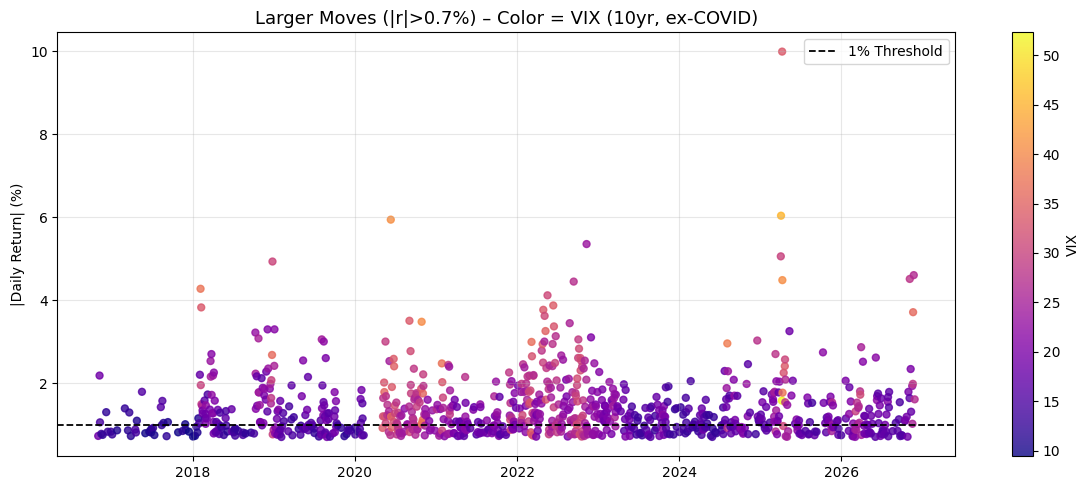

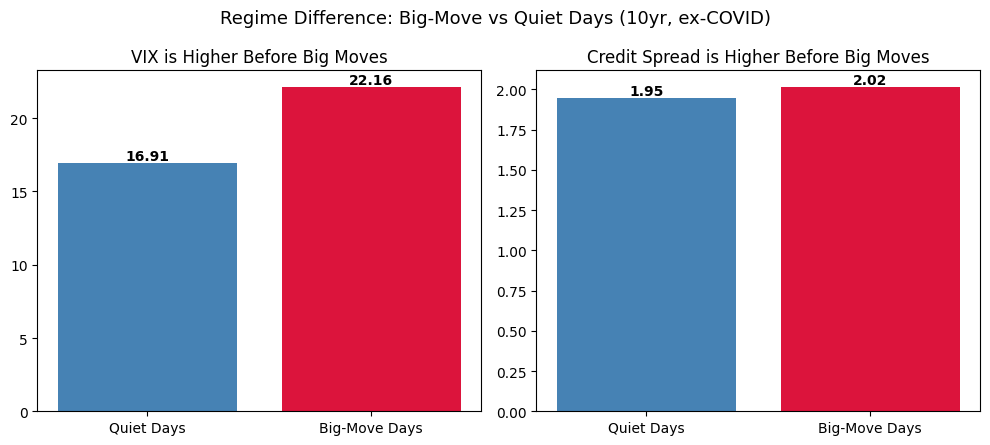

In [100]:
# ============================================================
# M12-C — TRENDING / CONTEXT VISUALS (rebuilt on final dataset)
# ============================================================

# --- 1. Price / VIX / 10Y Yield context (3-panel) ---
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(m12_data['datetime'], m12_data['close'], color='black', lw=1.1)
axes[0].set_ylabel('SPY Price'); axes[0].set_title('S&P 500 Context – Price, Volatility & Rates (10yr, ex-COVID)', fontsize=13)
axes[0].grid(True, alpha=0.3)
axes[1].plot(m12_data['datetime'], m12_data['vix'], color='purple', lw=1.1)
axes[1].set_ylabel('VIX'); axes[1].grid(True, alpha=0.3)
axes[2].plot(m12_data['datetime'], m12_data['t10'], color='green', lw=1.1)
axes[2].set_ylabel('10Y Yield'); axes[2].grid(True, alpha=0.3)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# --- 2. Magnitude vs 1% threshold + VIX (dual panel) ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios':[1.2,1]})
ret_pct = m12_data['log_ret'].abs() * 100
ax1.fill_between(m12_data['datetime'], ret_pct, color='crimson', alpha=0.4)
ax1.axhline(1.0, color='black', linestyle='--', lw=1.3, label='1% Big-Move Threshold')
ax1.set_ylabel('|Daily Return| (%)'); ax1.set_title('SPY Move Magnitude (10yr, ex-COVID)', fontsize=13)
ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(m12_data['datetime'], m12_data['vix'], color='purple', lw=1.1)
ax2.set_ylabel('VIX'); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# --- 3. Price with Big-Move markers + VIX ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios':[1.4,1]})
ax1.plot(m12_data['datetime'], m12_data['close'], color='black', lw=1.0, label='SPY')
big = m12_data[m12_data['target'] == 1]
ax1.scatter(big['datetime'], big['close'], color='red', s=14, zorder=5, label='Next-day Big Move')
ax1.set_ylabel('SPY Price'); ax1.set_title('SPY Price – Red dots = Next-day Big Move (10yr, ex-COVID)', fontsize=13)
ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(m12_data['datetime'], m12_data['vix'], color='purple', lw=1.1)
ax2.set_ylabel('VIX'); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# --- 4. Larger moves only, colored by VIX ---
mask = m12_data['log_ret'].abs() > 0.007
subset = m12_data[mask].copy()
subset['ret_pct'] = subset['log_ret'].abs() * 100
fig, ax = plt.subplots(figsize=(12, 5))
sc = ax.scatter(subset['datetime'], subset['ret_pct'], c=subset['vix'], cmap='plasma', s=25, alpha=0.8)
ax.axhline(1.0, color='black', linestyle='--', lw=1.3, label='1% Threshold')
ax.set_ylabel('|Daily Return| (%)'); ax.set_title('Larger Moves (|r|>0.7%) – Color = VIX (10yr, ex-COVID)', fontsize=13)
plt.colorbar(sc, ax=ax, label='VIX'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# --- 5. VIX / Credit Spread: Big-Move vs Quiet days ---
big_days = m12_data[m12_data['target'] == 1]
quiet_days = m12_data[m12_data['target'] == 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, col, title in [(axes[0], 'vix', 'VIX'), (axes[1], 'credit_spread', 'Credit Spread')]:
    vals = [quiet_days[col].mean(), big_days[col].mean()]
    ax.bar(['Quiet Days','Big-Move Days'], vals, color=['steelblue','crimson'])
    ax.set_title(f'{title} is Higher Before Big Moves')
    for i, v in enumerate(vals):
        ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')
plt.suptitle('Regime Difference: Big-Move vs Quiet Days (10yr, ex-COVID)', fontsize=13)
plt.tight_layout(); plt.show()

In [101]:
# ============================================================
# FINAL SUMMARY — paste as the LAST cell, after Section 12
# Just reads variables already set by Sections 08 and 10 above;
# run this notebook top-to-bottom (Runtime -> Run all) first.
# ============================================================
print("=" * 70)
print("TODAY'S RECOMMENDATION")
print("=" * 70)
print(f"Data as of:            {m8_as_of}")
print(f"Forecast applies to:   {m8_next_session.date()}")
print(f"Model P(Big Move):     {m8_prob:.1%}  (threshold: {M4_THRESHOLD:.1%})")
print(f"Big-Move call:         {'ELEVATED RISK' if m8_prob >= M4_THRESHOLD else 'NEUTRAL / CASH BIAS'}")
print(f"Condor guardrail:      {'CONDOR ALLOWED - small size only' if m10_all_pass else 'NO CONDOR - stay cash / flat'}")
print("=" * 70)
print("This is a risk-awareness filter, not a directional signal.")
print("See the Disclaimer Cell at the top for what this model is and is not.")

TODAY'S RECOMMENDATION
Data as of:            2026-11-27
Forecast applies to:   2026-11-30
Model P(Big Move):     66.0%  (threshold: 54.4%)
Big-Move call:         ELEVATED RISK
Condor guardrail:      NO CONDOR - stay cash / flat
This is a risk-awareness filter, not a directional signal.
See the Disclaimer Cell at the top for what this model is and is not.


In [102]:
# ============================================================
# CHECK — is the most recent EXPECTED trading day's bar posted?
# Generalized: correctly skips weekends and NYSE holidays when
# determining what "today's bar" should even be.
# Standalone — run this by itself, no dependency on anything else.
# ============================================================
import yfinance as yf
from datetime import datetime, timedelta

# --- Yearly config: update once a year from nyse.com holiday schedule ---
NYSE_HOLIDAYS_2026 = [
    '2026-01-01', '2026-01-19', '2026-02-16', '2026-04-03',
    '2026-05-25', '2026-06-19', '2026-07-03', '2026-09-07',
    '2026-11-26', '2026-12-25',
]
NYSE_HOLIDAYS = set(NYSE_HOLIDAYS_2026)  # extend with more years as needed

def chk_is_trading_day(d):
    return d.weekday() < 5 and d.strftime('%Y-%m-%d') not in NYSE_HOLIDAYS

def chk_last_expected_trading_day(from_date):
    """Walks backward from from_date (inclusive) to the most recent trading day."""
    d = from_date
    while not chk_is_trading_day(d):
        d -= timedelta(days=1)
    return d.date()

chk_now = datetime.today()
chk_expected = chk_last_expected_trading_day(chk_now)

chk_start = chk_now - timedelta(days=10)
chk_spy = yf.download("SPY", start=chk_start, end=chk_now, progress=False)
chk_latest_date = chk_spy.index[-1].date()

print(f"Most recent available SPY daily bar: {chk_latest_date}")
print(f"Most recent EXPECTED trading day:    {chk_expected}")

if chk_latest_date >= chk_expected:
    print("\n✅ Latest expected trading day IS posted — safe to Run All.")
else:
    print(f"\n⏳ Not posted yet — most recent bar is still {chk_latest_date}, "
          f"but {chk_expected} is expected to exist by now. Wait and re-check.")

Most recent available SPY daily bar: 2026-11-27
Most recent EXPECTED trading day:    2026-11-27

✅ Latest expected trading day IS posted — safe to Run All.


In [103]:
import yfinance as yf
print(yf.download("SPY", period="5d", progress=False).tail())

Price            Close        High         Low        Open     Volume
Ticker             SPY         SPY         SPY         SPY        SPY
Date                                                                 
2026-11-20  689.809998  718.289978  686.750000  713.559998  151413300
2026-11-23  722.289978  727.979980  713.530029  724.330017   88283800
2026-11-24  718.780029  720.929993  712.140015  715.150024   64343200
2026-11-25  716.700012  718.429993  695.450012  703.200012   73112800
2026-11-27  728.320007  729.150024  719.609985  725.859985   40442200
